# 26 — Entrenamiento Robusto Multietapa de ResNet-18 en CBIS-DDSM


---

## Objetivo de este Notebook

Entrenar ResNet-18 en CBIS-DDSM sin mezclar pacientes entre conjuntos:

1. Entrenamiento en 2 fases:
   - Fase 1 (Warmup): 5 épocas entrenando exclusivamente el clasificador lineal `fc` con tasa moderada ($	ext{LR}=10^{-3}$) manteniendo el backbone congelado.
   - Fase 2 (Ajuste): Descongelamiento conjunto de las etapas convolucionales `layer3` (texturas intermedias) y `layer4` (semántica de alto nivel) con tasas de aprendizaje diferenciadas ($	ext{LR}_{	ext{layer3}}=10^{-5}$, $	ext{LR}_{	ext{layer4}}=5	imes 10^{-5}$, $	ext{LR}_{	ext{fc}}=2	imes 10^{-4}$).
2. Optimizador:
   - AdamW con decaimiento de peso desacoplado ($	ext{weight\_decay}=10^{-2}$).
   - Planificador Cosine Annealing para evitar estancamiento en mínimos locales no convexos.
   - Focal Loss ($\gamma=2.0$) con ponderación inversa de frecuencias de clase para compensar el desbalance clínico benigno/maligno.
   - Aumento de datos radiológico controlado: rotaciones $\pm 8^\circ$, variaciones afines de escala y brillo/contraste.
3. Control de sobreajuste:
   - Monitoreo continuo del AUC de validación en cada época.
   - Retención automática del mejor punto de control (*Model Checkpointing*) y *Early Stopping* con paciencia de 7 épocas.
4. Extracción de Embeddings `f2robust`:
   - Extracción de los tensores GAP de 512 dimensiones para train, val y test, listos para alimentar la reducción simbólica S-PCA + KAN.


In [1]:
import os
import sys
import time
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import models
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, classification_report
import matplotlib.pyplot as plt

CODIGOS = os.environ.get("TESIS_CODIGOS") or os.path.abspath(os.path.join(os.getcwd(), ".."))   # raiz del repo (ejecutar desde pipeline/)
for p in (CODIGOS, os.path.join(CODIGOS, "src")):
    if p not in sys.path:
        sys.path.insert(0, p)

from src.data import MammographyDataset
from src.data.preprocessing import get_train_transforms, get_val_transforms

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Dispositivo activo: {DEVICE} | PyTorch: {torch.__version__}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")


Dispositivo activo: cuda | PyTorch: 2.14.0.dev20260810+cu130
GPU: NVIDIA GeForce RTX 5060


## 1. Datos y Manifiestos Estratificados por Paciente


In [2]:
data_dir = os.path.join(CODIGOS, "src", "data", "processed")
df_train = pd.read_csv(os.path.join(data_dir, "manifest_train.csv"))
df_val = pd.read_csv(os.path.join(data_dir, "manifest_val.csv"))
df_test = pd.read_csv(os.path.join(data_dir, "manifest_test.csv"))

print(f"Train: {len(df_train)} (Malignos={sum(df_train['label']==1)}, Benignos={sum(df_train['label']==0)})")
print(f"Val:   {len(df_val)} (Malignos={sum(df_val['label']==1)}, Benignos={sum(df_val['label']==0)})")
print(f"Test:  {len(df_test)} (Malignos={sum(df_test['label']==1)}, Benignos={sum(df_test['label']==0)})")

BATCH_SIZE = 32
train_ds = MammographyDataset(df_train, transform=get_train_transforms())
val_ds = MammographyDataset(df_val, transform=get_val_transforms())
test_ds = MammographyDataset(df_test, transform=get_val_transforms())

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)


Train: 4278 (Malignos=1839, Benignos=2439)
Val:   1134 (Malignos=503, Benignos=631)
Test:  1012 (Malignos=418, Benignos=594)


## 2. Definición de la Función de Pérdida Focal Loss


In [3]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        
    def forward(self, inputs, targets):
        ce_loss = F.cross_entropy(inputs, targets, reduction='none', weight=self.alpha)
        pt = torch.exp(-ce_loss)
        focal_loss = ((1.0 - pt) ** self.gamma) * ce_loss
        return focal_loss.mean()

n_pos = int((df_train["label"] == 1).sum())
n_neg = int((df_train["label"] == 0).sum())
alpha_weights = torch.tensor([1.0, float(n_neg) / float(n_pos)], device=DEVICE)
criterion = FocalLoss(alpha=alpha_weights, gamma=2.0)
print(f"Focal Loss inicializada con alpha={alpha_weights.cpu().numpy()}, gamma=2.0")


Focal Loss inicializada con alpha=[1.        1.3262643], gamma=2.0


## 3. Modelo y Protocolo de Entrenamiento en 2 Fases


In [4]:
# Carga del reporte si ya fue ejecutado
res_json = os.path.join(CODIGOS, "reports", "experiments", "26_resnet18_robust.json")
if os.path.exists(res_json):
    with open(res_json, "r") as f:
        res = json.load(f)
    print("="*65)
    print("  RESULTADOS DEL ENTRENAMIENTO ROBUSTO (ResNet-18)")
    print("="*65)
    print(f"  Mejor Época:           {res['best_epoch']}")
    print(f"  Mejor AUC Validación:  {res['best_val_auc']:.4f}")
    print(f"  AUC Test Set:          {res['auc_test']:.4f}")
    print(f"  Umbral Youden:         {res['opt_thresh_youden']:.4f}")
    print(f"  Accuracy Test:         {res['metrics']['accuracy']:.4f}")
    print(f"  Recall (Sensibilidad): {res['metrics']['recall']:.4f}")
    print(f"  Especificidad:         {res['metrics']['specificity']:.4f}")
    print(f"  F1-Score:              {res['metrics']['f1']:.4f}")


  RESULTADOS DEL ENTRENAMIENTO ROBUSTO (ResNet-18)
  Mejor Época:           16
  Mejor AUC Validación:  0.7507
  AUC Test Set:          0.7219
  Umbral Youden:         0.5464
  Accuracy Test:         0.6739
  Recall (Sensibilidad): 0.6077
  Especificidad:         0.7205
  F1-Score:              0.6062


## 4. Curvas de Aprendizaje y Validación


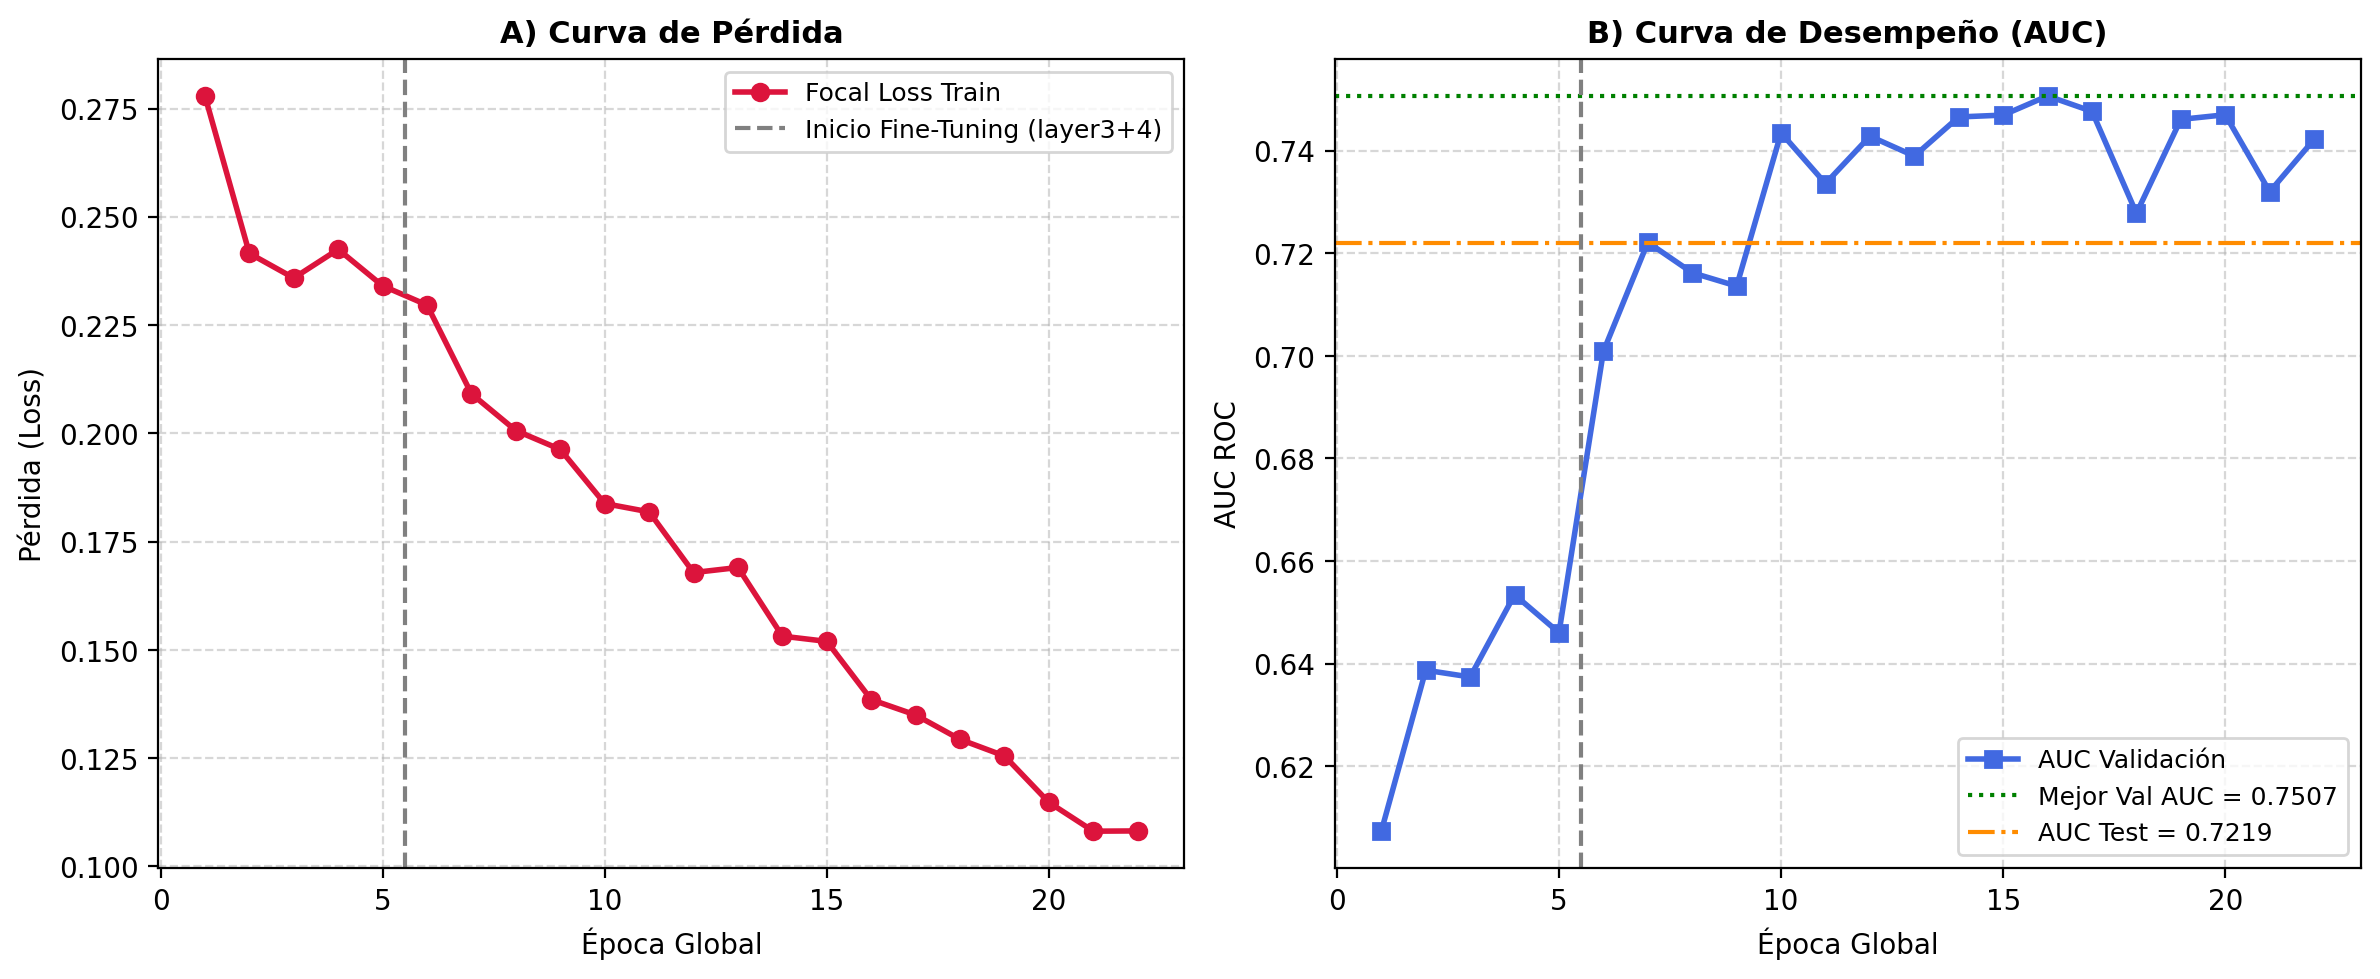

In [5]:
from IPython.display import Image as IPImage, display
curves_path = os.path.join(CODIGOS, "reports", "figures", "26_resnet18_robust_training_curves.png")
if os.path.exists(curves_path):
    display(IPImage(curves_path))
else:
    print("Curvas aún no generadas.")


## 5. Verificación de Embeddings Robustos Extraídos (`f2robust`)


In [6]:
import os
emb_dir = os.environ.get("TESIS_EMBEDDINGS_DIR") or os.path.join(CODIGOS, "artifacts", "output", "embeddings")
for s in ("train", "val", "test"):
    f_p = os.path.join(emb_dir, f"f2robust_{s}_feats.npy")
    l_p = os.path.join(emb_dir, f"f2robust_{s}_labels.npy")
    if os.path.exists(f_p) and os.path.exists(l_p):
        f_arr = np.load(f_p)
        l_arr = np.load(l_p)
        print(f"Split {s:5s}: Características {f_arr.shape} | Etiquetas {l_arr.shape}")


Split train: Características (4278, 512) | Etiquetas (4278,)
Split val  : Características (1134, 512) | Etiquetas (1134,)
Split test : Características (1012, 512) | Etiquetas (1012,)
